# 04. DistilBERT Fine-Tuning Pipeline

- **Role/Owner:** Member 2 (ML & Data Engineering Lead)
- **Core Responsibility:** Fine-tune `distilbert-base-uncased` Transformer on combined PHEME + FakeNewsNet political dataset with weighted cross-entropy loss.
- **Key Interface/Contract:** Consumes cleaned text datasets; outputs fine-tuned PyTorch checkpoint (`backend/models/distilbert_finetuned/`).

**Inputs:** `backend/data/processed/{train,val,test}.csv` from notebook 02 (`text_clean`, `label` with 1 = misinformation / rumour, `source`, `event`), the TF-IDF reference numbers in `backend/reports/split_baselines.md`, and the evaluation-only contrast set `backend/data/eval/contrast_set.csv`.

**Outputs:**
- `backend/models/distilbert_finetuned/`: FP32 model and tokenizer (`save_pretrained`), consumed by notebook 05. Gitignored.
- `backend/reports/distilbert_results.md`: test metrics, per-source scores, unseen-event table, Control Test and contrast set.
- `backend/reports/distilbert_metrics.json`: the same numbers for `GET /api/metrics` and notebook 05.

**Where it runs:** a Google Colab T4 GPU (the first code cell clones the repo and pins `transformers` to match `ml-env`). The same notebook runs locally in the `ml-env` kernel on Apple MPS as a fallback; the first local run downloads the DistilBERT weights (about 268 MB).

**Evaluation protocol:** model selection uses validation Macro F1 only; the test split is scored once. The unseen-event runs reuse notebook 02 Part 10: hold out each PHEME event with at least 100 threads, train on everything else, score on the held-out event.

In [13]:
# Role/Owner: Member 2 (ML & Data Engineering Lead)
# Core Responsibility: Transformer fine-tuning on political misinformation data
# Key Interface/Contract: Input: cleaned splits -> Output: fine-tuned DistilBERT weights

# Colab setup: clone the repo so relative paths and the preprocessor import work as they do locally.
# Does nothing outside Colab.
import os
import subprocess
import sys

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/PhamAn0910/COS30049-political-misinfo.git'
COLAB_REPO_DIR = '/content/inno'

if IN_COLAB:
    if not os.path.isdir(COLAB_REPO_DIR):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, COLAB_REPO_DIR], check=True)
    os.chdir(f'{COLAB_REPO_DIR}/backend/notebooks')
    # Match ml-env so the saved model loads locally without version drift; Colab's torch is kept.
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers==5.18.0'], check=True)

print('Running on Colab' if IN_COLAB else 'Running locally', '| cwd:', os.getcwd())

Running on Colab | cwd: /content/inno/backend/notebooks


In [2]:
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')  # must be set before torch is imported

# torch is imported before sklearn on purpose: in ml-env both ship their own libomp, and loading sklearn's first
# makes torch's CPU kernels segfault.
import torch

import gc
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import transformers
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score)
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          get_linear_schedule_with_warmup)

sys.path.insert(0, '..')  # make backend/ importable so the service module is the single source of truth
from app.services.preprocessor import preprocess_political_text

MODEL_NAME = 'distilbert-base-uncased'
MAX_LENGTH = 256
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
EPOCHS = 3
WARMUP_RATIO = 0.1
MAX_GRAD_NORM = 1.0
SEED = 42
MIN_EVENT_THREADS = 100

LABELS = {0: 'factual', 1: 'misinformation'}
DATA_DIR = Path('../data/processed')
REPORTS_DIR = Path('../reports')
OUTPUT_DIR = Path('../models/distilbert_finetuned')
RESULTS_PATH = REPORTS_DIR / 'distilbert_results.md'
METRICS_PATH = REPORTS_DIR / 'distilbert_metrics.json'


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    DEVICE_NAME = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    DEVICE, DEVICE_NAME = torch.device('mps'), 'Apple MPS'
else:
    DEVICE, DEVICE_NAME = torch.device('cpu'), 'CPU'

if IN_COLAB:
    assert DEVICE.type == 'cuda', 'This Colab runtime has no GPU: Runtime > Change runtime type > T4 GPU, then rerun.'

print(f'torch {torch.__version__} | transformers {transformers.__version__} | sklearn {sklearn.__version__}')
print(f'Device: {DEVICE} ({DEVICE_NAME})')

torch 2.11.0+cu130 | transformers 5.18.0 | sklearn 1.6.1
Device: cuda (Tesla T4)


## Part 1: Data

The deduped splits from notebook 02. Row counts and labels are asserted so a stale CSV fails here, not halfway through training. The TF-IDF numbers are read from `split_baselines.md`, so the comparison always uses the baseline notebook 02 last wrote.

In [3]:
train_df, val_df, test_df = (pd.read_csv(DATA_DIR / f'{name}.csv') for name in ('train', 'val', 'test'))
for df in (train_df, val_df, test_df):
    df['text_clean'] = df['text_clean'].fillna('')

assert (len(train_df), len(val_df), len(test_df)) == (5079, 1088, 1089), 'split sizes changed: re-check notebook 02'
assert all(set(df['label'].unique()) <= {0, 1} for df in (train_df, val_df, test_df))


def read_tfidf_baselines(path: Path) -> tuple[float, float, dict[str, float]]:
    # Random-split and unseen-event Macro F1 of 'TF-IDF on cleaned text', plus its per-event table.
    lines = path.read_text().splitlines()
    cells = lambda line: [c.strip() for c in line.strip().strip('|').split('|')]
    summary = cells(next(l for l in lines if l.startswith('| TF-IDF on cleaned text |')))
    per_event, header = {}, None
    for line in lines[lines.index('## Per-event Macro F1 (held-out event)') + 1:]:
        if not line.startswith('|'):
            if header:
                break
            continue
        row = cells(line)
        if header is None:
            header = row
        elif not set(row[0]) <= set('-'):
            per_event[row[0]] = float(row[header.index('TF-IDF')])
    return float(summary[1]), float(summary[2]), per_event


TFIDF_RANDOM_F1, TFIDF_UNSEEN_F1, TFIDF_PER_EVENT = read_tfidf_baselines(REPORTS_DIR / 'split_baselines.md')
print(f'TF-IDF baseline: random split {TFIDF_RANDOM_F1:.3f}, unseen events {TFIDF_UNSEEN_F1:.3f}')

split_summary = pd.DataFrame([
    {'split': name, 'rows': len(df), 'misinformation rate': df['label'].mean(),
     'pheme': int((df['source'] == 'pheme').sum()), 'politifact': int((df['source'] == 'politifact').sum())}
    for name, df in (('train', train_df), ('val', val_df), ('test', test_df))])
display(split_summary.round(3))

TF-IDF baseline: random split 0.843, unseen events 0.597


,split,rows,misinformation rate,pheme,politifact
0,train,5079,0.382,4392,687
1,val,1088,0.381,941,147
2,test,1089,0.382,942,147


## Part 2: Tokenization

`MAX_LENGTH = 256` keeps `settings.token_max_length` from the API config. Cleaned texts are short, so batches are padded dynamically to the longest text in the batch (`DataCollatorWithPadding`) instead of to 256, which keeps training fast without truncating anything.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

all_texts = pd.concat([train_df, val_df, test_df])['text_clean'].tolist()
token_lengths = np.array([len(ids) for ids in tokenizer(all_texts)['input_ids']])
print(f'Token length (with [CLS]/[SEP]) over {len(token_lengths):,} texts: '
      f'P50 {np.percentile(token_lengths, 50):.0f}, P95 {np.percentile(token_lengths, 95):.0f}, '
      f'max {token_lengths.max()}, over {MAX_LENGTH}: {(token_lengths > MAX_LENGTH).sum()}')


class ClaimDataset(Dataset):
    def __init__(self, df: pd.DataFrame):
        self.encodings = tokenizer(df['text_clean'].tolist(), truncation=True, max_length=MAX_LENGTH)
        self.labels = df['label'].tolist()

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, i: int) -> dict:
        item = {key: values[i] for key, values in self.encodings.items()}
        item['labels'] = self.labels[i]
        return item


collator = DataCollatorWithPadding(tokenizer)


def make_loader(df: pd.DataFrame, shuffle: bool) -> DataLoader:
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ClaimDataset(df), batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collator,
                      generator=generator)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Token length (with [CLS]/[SEP]) over 7,256 texts: P50 26, P95 35, max 72, over 256: 0


## Part 3: Training helpers

A plain PyTorch loop instead of the Hugging Face `Trainer`: `Trainer` needs `accelerate` and a subclass for weighted loss, while this loop is short and shows every step.

- **Weighted cross-entropy:** misinformation is about 38% of the training rows, so each class is weighted by its inverse frequency, normalised to sum to 2: `w = 1 / counts; w = w / w.sum() * 2`.
- **Optimiser:** AdamW with linear warm-up over the first 10% of steps, then linear decay; gradients clipped to norm 1.0 (the `Trainer` default).
- The same `train_one_epoch()` and `predict_proba()` are reused by the main run and the unseen-event runs.

In [5]:
def class_weights(labels: pd.Series) -> torch.Tensor:
    counts = np.bincount(labels, minlength=2).astype(float)
    weights = 1 / counts
    return torch.tensor(weights / weights.sum() * 2, dtype=torch.float)


def new_model() -> torch.nn.Module:
    return AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=LABELS, label2id={v: k for k, v in LABELS.items()}).to(DEVICE)


def make_optimizer(model: torch.nn.Module, total_steps: int):
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    return optimizer, scheduler


def train_one_epoch(model, loader, optimizer, scheduler, loss_fn) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = {key: value.to(DEVICE) for key, value in batch.items()}
        labels = batch.pop('labels')
        loss = loss_fn(model(**batch).logits, labels)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item() * len(labels)
    mean_loss = total_loss / len(loader.dataset)
    assert np.isfinite(mean_loss), f'training loss is {mean_loss}'
    return mean_loss


@torch.inference_mode()
def predict_proba(model, loader) -> np.ndarray:
    model.eval()
    probs = []
    for batch in loader:
        batch = {key: value.to(DEVICE) for key, value in batch.items() if key != 'labels'}
        probs.append(torch.softmax(model(**batch).logits, dim=-1).float().cpu().numpy())
    return np.concatenate(probs)


def free_memory() -> None:
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    elif DEVICE.type == 'mps':
        torch.mps.empty_cache()


print('Class weights (factual, misinformation):', class_weights(train_df['label']).numpy().round(3))

Class weights (factual, misinformation): [0.763 1.237]


## Part 4: Fine-tuning on the training split

Three epochs; after each one the model is scored on the validation split. The weights of the epoch with the best validation Macro F1 are kept, and `best_epoch` is reused for the unseen-event runs.

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.5172 | val Macro F1 0.7831 | 30s
epoch 2: train loss 0.3207 | val Macro F1 0.8614 | 28s
epoch 3: train loss 0.2229 | val Macro F1 0.8700 | 27s
Best epoch 3 (val Macro F1 0.8700); training took 1.4 min


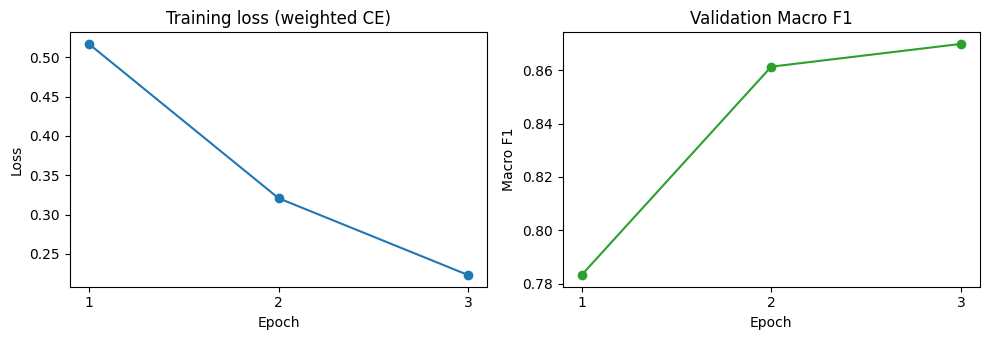

In [6]:
set_seed(SEED)
train_loader, val_loader, test_loader = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)
model = new_model()
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights(train_df['label']).to(DEVICE))
optimizer, scheduler = make_optimizer(model, len(train_loader) * EPOCHS)

history, best_val_f1, best_epoch, best_state = [], -1.0, None, None
train_start = time.time()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, loss_fn)
    val_f1 = f1_score(val_df['label'], predict_proba(model, val_loader).argmax(axis=1), average='macro')
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_macro_f1': val_f1})
    if val_f1 > best_val_f1:
        best_val_f1, best_epoch = val_f1, epoch
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
    print(f'epoch {epoch}: train loss {train_loss:.4f} | val Macro F1 {val_f1:.4f} | {time.time() - epoch_start:.0f}s')
train_minutes = (time.time() - train_start) / 60
print(f'Best epoch {best_epoch} (val Macro F1 {best_val_f1:.4f}); training took {train_minutes:.1f} min')

history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history_df['epoch'], history_df['train_loss'], marker='o')
axes[0].set(title='Training loss (weighted CE)', xlabel='Epoch', ylabel='Loss', xticks=history_df['epoch'])
axes[1].plot(history_df['epoch'], history_df['val_macro_f1'], marker='o', color='tab:green')
axes[1].set(title='Validation Macro F1', xlabel='Epoch', ylabel='Macro F1', xticks=history_df['epoch'])
plt.tight_layout()
plt.show()

## Part 5: Test-set evaluation (scored once)

The best-epoch weights are restored and the untouched test split is scored. Positive class = misinformation.

                precision    recall  f1-score   support

       factual      0.898     0.880     0.889       673
misinformation      0.812     0.839     0.825       416

      accuracy                          0.864      1089
     macro avg      0.855     0.859     0.857      1089
  weighted avg      0.865     0.864     0.865      1089

Macro F1: DistilBERT 0.857 vs TF-IDF 0.843 (+0.014)


,Source,Rows,Misinformation rate,Macro F1
0,pheme,942,0.374,0.857
1,politifact,147,0.435,0.857


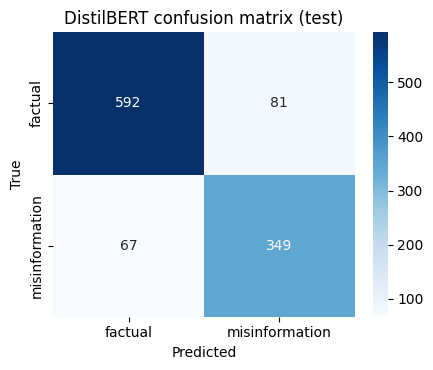

In [7]:
model.load_state_dict(best_state)
test_probs = predict_proba(model, test_loader)
test_pred = test_probs.argmax(axis=1)
y_test = test_df['label'].to_numpy()

test_metrics = {
    'accuracy': accuracy_score(y_test, test_pred),
    'precision': precision_score(y_test, test_pred, average='macro'),
    'recall': recall_score(y_test, test_pred, average='macro'),
    'macro_f1': f1_score(y_test, test_pred, average='macro'),
}
tn, fp, fn, tp = (int(v) for v in confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel())
print(classification_report(y_test, test_pred, target_names=list(LABELS.values()), digits=3))
print(f"Macro F1: DistilBERT {test_metrics['macro_f1']:.3f} vs TF-IDF {TFIDF_RANDOM_F1:.3f} "
      f"({test_metrics['macro_f1'] - TFIDF_RANDOM_F1:+.3f})")

per_source = pd.DataFrame([
    {'Source': source, 'Rows': int(mask.sum()), 'Misinformation rate': y_test[mask].mean(),
     'Macro F1': f1_score(y_test[mask], test_pred[mask], average='macro')}
    for source in ('pheme', 'politifact') for mask in [(test_df['source'] == source).to_numpy()]])
display(per_source.round(3))

plt.figure(figsize=(4.5, 3.8))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cmap='Blues',
            xticklabels=list(LABELS.values()), yticklabels=list(LABELS.values()))
plt.title('DistilBERT confusion matrix (test)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()

## Part 6: Events the model never saw

Same protocol as notebook 02 Part 10, so the numbers sit beside TF-IDF directly. For each PHEME event with at least 100 threads: a fresh DistilBERT is trained on every other PHEME event plus the PolitiFact training rows, for `best_epoch` epochs with the same hyperparameters and class weights recomputed on that fit set, then scored on the held-out event. No validation-based selection happens here, because the held-out event must not influence training.

In [8]:
pheme_pool = pd.concat([train_df, val_df, test_df]).query("source == 'pheme'")
event_sizes = pheme_pool['event'].value_counts()
held_out_events = sorted(event_sizes[event_sizes >= MIN_EVENT_THREADS].index)
politifact_train = train_df[train_df['source'] == 'politifact']
assert set(held_out_events) == set(TFIDF_PER_EVENT), 'held-out events differ from split_baselines.md'

event_rows = []
unseen_start = time.time()
for event in held_out_events:
    set_seed(SEED)
    fit_df = pd.concat([pheme_pool[pheme_pool['event'] != event], politifact_train])
    eval_df = pheme_pool[pheme_pool['event'] == event]
    event_model = new_model()
    fit_loader = make_loader(fit_df, True)
    event_loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights(fit_df['label']).to(DEVICE))
    event_optimizer, event_scheduler = make_optimizer(event_model, len(fit_loader) * best_epoch)
    for _ in range(best_epoch):
        train_one_epoch(event_model, fit_loader, event_optimizer, event_scheduler, event_loss_fn)
    event_pred = predict_proba(event_model, make_loader(eval_df, False)).argmax(axis=1)
    event_rows.append({
        'Event': event, 'Threads': len(eval_df), 'Rumour': int(eval_df['label'].sum()),
        'Non-rumour': int((eval_df['label'] == 0).sum()),
        'DistilBERT': f1_score(eval_df['label'], event_pred, average='macro'),
        'TF-IDF': TFIDF_PER_EVENT[event],
    })
    print(f"{event}: DistilBERT {event_rows[-1]['DistilBERT']:.3f} | TF-IDF {TFIDF_PER_EVENT[event]:.3f}")
    del event_model, event_optimizer, event_scheduler, fit_loader
    free_memory()

event_df = pd.DataFrame(event_rows)
unseen_f1 = event_df['DistilBERT'].mean()
print(f'Unseen-event runs took {(time.time() - unseen_start) / 60:.1f} min')
print(f'Mean over {len(event_df)} events: DistilBERT {unseen_f1:.3f} vs TF-IDF {event_df["TF-IDF"].mean():.3f}')
display(event_df.round(3))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


charliehebdo-all-rnr-threads: DistilBERT 0.751 | TF-IDF 0.749


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

putinmissing-all-rnr-threads: DistilBERT 0.659 | TF-IDF 0.504


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


sydneysiege-all-rnr-threads: DistilBERT 0.745 | TF-IDF 0.717
Unseen-event runs took 12.3 min
Mean over 8 events: DistilBERT 0.622 vs TF-IDF 0.597


,Event,Threads,Rumour,Non-rumour,DistilBERT,TF-IDF
0,charliehebdo-all-rnr-threads,2026,446,1580,0.751,0.749
1,ferguson-all-rnr-threads,1115,279,836,0.644,0.590
2,germanwings-crash-all-rnr-threads,466,235,231,0.637,0.738
3,gurlitt-all-rnr-threads,122,52,70,0.536,0.566
4,ottawashooting-all-rnr-threads,879,465,414,0.713,0.716
5,prince-toronto-all-rnr-threads,224,220,4,0.291,0.195
6,putinmissing-all-rnr-threads,233,121,112,0.659,0.504
7,sydneysiege-all-rnr-threads,1197,512,685,0.745,0.717


## Part 7: Control Test

The three demo sentences from the project plan (`docs/political-misinfo-plan.md`, "The Control Test"), cleaned by the same `preprocess_political_text` the API uses. The outcome is recorded as it is; the model is not tuned to pass it.

In [9]:
CONTROL_TESTS = [
    ('Misinformation input',
     'BREAKING: Leaked documents confirm election officials destroyed 50,000 valid ballots overnight in swing state. '
     '#StopTheSteal #ElectionFraud SHARE NOW!!!', 'misinformation', 0.90),
    ('Factual input (same keywords)',
     'Election officials confirmed all 50,000 ballots were securely audited and counted following standard legal '
     'verification procedures, with bipartisan observers present throughout.', 'factual', 0.85),
    ('Edge case: sensational punctuation',
     "Ferguson police cover-up EXPOSED!!! Media won't tell you this!!! #Ferguson #TruthMatters",
     'misinformation', None),
]

model.eval()
control_rows = []
for name, text, expected, min_confidence in CONTROL_TESTS:
    cleaned = preprocess_political_text(text)
    encoded = tokenizer(cleaned, truncation=True, max_length=MAX_LENGTH, return_tensors='pt').to(DEVICE)
    with torch.inference_mode():
        probs = torch.softmax(model(**encoded).logits, dim=-1)[0].float().cpu().numpy()
    label = LABELS[int(probs.argmax())]
    passed = label == expected and (min_confidence is None or probs.max() >= min_confidence)
    control_rows.append({'Case': name, 'Cleaned text': cleaned, 'Expected': expected,
                         'Required confidence': '-' if min_confidence is None else f'>= {min_confidence:.0%}',
                         'Predicted': label, 'Confidence': float(probs.max()),
                         'P(misinformation)': float(probs[1]), 'Result': 'pass' if passed else 'fail'})

control_df = pd.DataFrame(control_rows)
display(control_df.drop(columns='Cleaned text').round(3))

,Case,Expected,Required confidence,Predicted,Confidence,P(misinformation),Result
0,Misinformation input,misinformation,>= 90%,misinformation,0.979,0.979,pass
1,Factual input (same keywords),factual,>= 85%,misinformation,0.618,0.618,fail
2,Edge case: sensational punctuation,misinformation,-,factual,0.983,0.017,fail


## Part 8: Contrast set

The Control Test has only three sentences, too few to tell a real improvement from luck. `backend/data/eval/contrast_set.csv` holds pairs that share a topic and keywords: one factual sentence and one misinformation sentence each. It is used **for evaluation only**, never for training or model selection, and is cleaned with the same `preprocess_political_text` as the API. Every factual row has a `fact_source` a reviewer can check.

- `style_aligned` pairs follow the Control Test pattern: the factual sentence is neutral and the misinformation is sensational (caps, `!!!`, calls to share).
- `style_crossed` pairs swap the styles: a sensational but true sentence against a neutral but false one. A model that only reads style gets both wrong.
- **Style-balanced accuracy** is the headline metric: the mean of the per-cell accuracies over the label x style cells present. Plain accuracy rewards style, because most pairs are style-aligned.
- **Regex style baseline:** predicts misinformation when the raw text has a 4+ letter all-caps word, `!!` or "share". A model reads more than style only if it beats this row on style-balanced accuracy.
- **Pair accuracy** counts a pair as right only when both of its sentences are classified correctly.

In [ ]:
def md_table(df: pd.DataFrame, floatfmt: str = '.3f') -> str:
    header = '| ' + ' | '.join(map(str, df.columns)) + ' |'
    sep = '|' + '|'.join('---' for _ in df.columns) + '|'
    fmt = lambda v: format(v, floatfmt) if isinstance(v, float) else (f'{v:,}' if isinstance(v, (int, np.integer)) else str(v))
    return '\n'.join([header, sep] + ['| ' + ' | '.join(fmt(v) for v in row) + ' |' for row in df.itertuples(index=False)])


CONTRAST_PATH = Path('../data/eval/contrast_set.csv')
contrast_df = pd.read_csv(CONTRAST_PATH)
assert (contrast_df.groupby('pair_id')['label'].apply(sorted).map(tuple) == (0, 1)).all(), \
    'each pair needs exactly one factual and one misinformation row'
contrast_df['text_clean'] = contrast_df['text'].map(preprocess_political_text)
contrast_probs = predict_proba(model, make_loader(contrast_df, False))
contrast_df['predicted'] = contrast_probs.argmax(axis=1)
contrast_df['p_misinformation'] = contrast_probs[:, 1]
contrast_df['correct'] = contrast_df['predicted'] == contrast_df['label']


def contrast_scores(df: pd.DataFrame) -> dict:
    return {'pairs': int(df['pair_id'].nunique()), 'accuracy': round(float(df['correct'].mean()), 4),
            'style_balanced_accuracy': round(float(df.groupby(['label', 'style'])['correct'].mean().mean()), 4),
            'macro_f1': round(float(f1_score(df['label'], df['predicted'], average='macro')), 4),
            'pair_accuracy': round(float(df.groupby('pair_id')['correct'].all().mean()), 4)}


def contrast_block(df: pd.DataFrame) -> dict:
    return {**contrast_scores(df), 'by_pair_type': {name: contrast_scores(g) for name, g in df.groupby('pair_type')}}


STYLE_REGEX = r'\b[A-Z]{4,}\b|!{2,}|(?i:\bshare\b)'
regex_df = contrast_df.assign(predicted=contrast_df['text'].str.contains(STYLE_REGEX, regex=True).astype(int))
regex_df['correct'] = regex_df['predicted'] == regex_df['label']

contrast_metrics = {'path': 'backend/data/eval/contrast_set.csv', **contrast_block(contrast_df),
                    'regex_baseline': {'pattern': STYLE_REGEX, **contrast_block(regex_df)}}
contrast_table = pd.DataFrame([
    {'Model': model_name, 'Subset': name, 'Pairs': scores['pairs'],
     'Style-balanced accuracy': scores['style_balanced_accuracy'], 'Accuracy': scores['accuracy'],
     'Macro F1': scores['macro_f1'], 'Pair accuracy': scores['pair_accuracy']}
    for model_name, df in (('DistilBERT', contrast_df), ('Regex style baseline', regex_df))
    for name, scores in ((name, contrast_scores(sub)) for name, sub in [('All', df)] + list(df.groupby('pair_type')))])
style_table = (contrast_df.assign(Label=contrast_df['label'].map(LABELS))
               .groupby(['Label', 'style'], sort=False)
               .agg(Rows=('correct', 'size'), Accuracy=('correct', 'mean'),
                    **{'Mean P(misinformation)': ('p_misinformation', 'mean')})
               .reset_index().rename(columns={'style': 'Style'}))
contrast_errors = (contrast_df[~contrast_df['correct']]
                   .assign(Expected=lambda d: d['label'].map(LABELS))
                   [['pair_id', 'pair_type', 'Expected', 'p_misinformation', 'text']]
                   .rename(columns={'pair_id': 'Pair', 'pair_type': 'Pair type',
                                    'p_misinformation': 'P(misinformation)', 'text': 'Text'}))
model_sba = contrast_metrics['style_balanced_accuracy']
regex_sba = contrast_metrics['regex_baseline']['style_balanced_accuracy']
NOISE_MARGIN = 0.10  # about the 95% interval of style-balanced accuracy on ~80 sentences
style_verdict = ('beats' if model_sba - regex_sba >= NOISE_MARGIN else
                 'does not beat' if regex_sba - model_sba >= NOISE_MARGIN else 'is within noise of')

display(contrast_table.round(3))
display(style_table.round(3))
display(contrast_errors.round(3))

contrast_section = f"""## Contrast set

`backend/data/eval/contrast_set.csv`: {contrast_metrics['pairs']} pairs that share a topic and keywords, one factual and
one misinformation sentence each, with a checkable `fact_source` for every factual row. Evaluation only, never used for
training or model selection. In `style_aligned` pairs the misinformation is sensational and the factual sentence
neutral (the Control Test pattern); in `style_crossed` pairs the styles are swapped, so a model that only reads style
gets both wrong. Pair accuracy counts a pair as right only when both sentences are.

**Headline: style-balanced accuracy**, the mean accuracy over the label x style cells. Plain accuracy rewards style,
because most pairs are style-aligned. The regex style baseline predicts misinformation when the text has a 4+ letter
all-caps word, `!!` or "share"; a model reads more than style only if it beats that row on style-balanced accuracy.
DistilBERT scores {model_sba:.3f} against the regex's {regex_sba:.3f}, so it {style_verdict} the style baseline
(gaps under {NOISE_MARGIN:.2f} are within the noise of a set this size).

{md_table(contrast_table)}

DistilBERT by label and writing style:

{md_table(style_table)}

Misclassified sentences ({len(contrast_errors)} of {len(contrast_df)}):

{md_table(contrast_errors)}
"""

## Part 9: Export

Saves the best-epoch model and tokenizer for notebook 05, then writes the metrics JSON (keys match `MetricsResponse`, plus the unseen-event results) and the results report.

In [10]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

hyperparameters = {'model_name': MODEL_NAME, 'max_length': MAX_LENGTH, 'batch_size': BATCH_SIZE,
                   'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY, 'epochs': EPOCHS,
                   'warmup_ratio': WARMUP_RATIO, 'max_grad_norm': MAX_GRAD_NORM, 'seed': SEED}
metrics = {
    **{key: round(float(value), 4) for key, value in test_metrics.items()},
    'confusion_matrix': {'true_positive': tp, 'false_positive': fp, 'true_negative': tn, 'false_negative': fn},
    'baseline_comparison': {'distilbert_macro_f1': round(float(test_metrics['macro_f1']), 4),
                            'tfidf_logreg_macro_f1': TFIDF_RANDOM_F1},
    'per_source_macro_f1': {s: round(float(f), 4) for s, f in zip(per_source['Source'], per_source['Macro F1'])},
    'unseen_event_macro_f1': round(float(unseen_f1), 4),
    'tfidf_unseen_event_macro_f1': TFIDF_UNSEEN_F1,
    'per_event': [{'event': r['Event'], 'threads': r['Threads'], 'rumour': r['Rumour'],
                   'non_rumour': r['Non-rumour'], 'distilbert_macro_f1': round(float(r['DistilBERT']), 4),
                   'tfidf_macro_f1': r['TF-IDF']} for r in event_rows],
    'control_test': [{'case': r['Case'], 'expected': r['Expected'], 'predicted': r['Predicted'],
                      'confidence': round(r['Confidence'], 4), 'result': r['Result']} for r in control_rows],
    'contrast_set': contrast_metrics,
    'best_epoch': best_epoch,
    'best_val_macro_f1': round(float(best_val_f1), 4),
    'training_history': [{'epoch': h['epoch'], 'train_loss': round(h['train_loss'], 4),
                          'val_macro_f1': round(float(h['val_macro_f1']), 4)} for h in history],
    'hyperparameters': hyperparameters,
    'torch_version': torch.__version__,
    'transformers_version': transformers.__version__,
    'device': DEVICE.type,
    'device_name': DEVICE_NAME,
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2) + '\n')
print(f'Saved model + tokenizer to {OUTPUT_DIR}: {sorted(p.name for p in OUTPUT_DIR.iterdir())}')
print(f'Wrote {METRICS_PATH}')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model + tokenizer to ../models/distilbert_finetuned: ['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']
Wrote ../reports/distilbert_metrics.json


In [11]:
test_table = pd.DataFrame([
    {'Metric': 'Accuracy', 'DistilBERT': test_metrics['accuracy'], 'TF-IDF': '-'},
    {'Metric': 'Precision (macro)', 'DistilBERT': test_metrics['precision'], 'TF-IDF': '-'},
    {'Metric': 'Recall (macro)', 'DistilBERT': test_metrics['recall'], 'TF-IDF': '-'},
    {'Metric': 'Macro F1', 'DistilBERT': test_metrics['macro_f1'], 'TF-IDF': TFIDF_RANDOM_F1},
])
event_table = pd.concat([event_df, pd.DataFrame([{
    'Event': '**Mean**', 'Threads': int(event_df['Threads'].sum()), 'Rumour': int(event_df['Rumour'].sum()),
    'Non-rumour': int(event_df['Non-rumour'].sum()), 'DistilBERT': unseen_f1, 'TF-IDF': TFIDF_UNSEEN_F1}])])
control_table = control_df[['Case', 'Expected', 'Required confidence', 'Predicted', 'Confidence', 'Result']]
kept_distilbert = unseen_f1 / test_metrics['macro_f1']
kept_tfidf = TFIDF_UNSEEN_F1 / TFIDF_RANDOM_F1
threshold_note = ('' if test_metrics['macro_f1'] >= 0.70 else
                  '\n**Below the project-plan risk threshold:** test Macro F1 is under 0.70.\n')

report = f"""# DistilBERT Fine-Tuning Results

Generated by `backend/notebooks/04_distilbert_finetune.ipynb`. Re-run the notebook to refresh it.

## Setup

`{MODEL_NAME}` fine-tuned on the deduped `train` split (5,079 rows), with weighted cross-entropy
(class weights {class_weights(train_df['label']).numpy().round(3).tolist()} for factual, misinformation), AdamW,
linear warm-up and decay. The epoch with the best validation Macro F1 was kept; the test split was scored once.

{md_table(pd.DataFrame([(k, str(v)) for k, v in hyperparameters.items()], columns=['Hyperparameter', 'Value']))}

Environment: torch {torch.__version__}, transformers {transformers.__version__}, device `{DEVICE.type}` ({DEVICE_NAME}).
Training took {train_minutes:.1f} min; best epoch {best_epoch} of {EPOCHS} (validation Macro F1 {best_val_f1:.3f}).

{md_table(history_df.rename(columns={'epoch': 'Epoch', 'train_loss': 'Train loss', 'val_macro_f1': 'Val Macro F1'}), '.4f')}

## Test split (random split)

{md_table(test_table)}
{threshold_note}
Confusion matrix (positive = misinformation): TP {tp}, FP {fp}, TN {tn}, FN {fn}.

Macro F1 by source:

{md_table(per_source)}

## Events the model never saw

Same protocol as `split_baselines.md`: each PHEME event with at least {MIN_EVENT_THREADS} threads is held out in turn; the model
is trained for {best_epoch} epoch(s) on the other PHEME events plus the PolitiFact training rows, without validation-based selection.

{md_table(event_table)}

DistilBERT keeps {kept_distilbert:.0%} of its random-split Macro F1 on events it never saw ({test_metrics['macro_f1']:.3f} to
{unseen_f1:.3f}); TF-IDF keeps {kept_tfidf:.0%} ({TFIDF_RANDOM_F1:.3f} to {TFIDF_UNSEEN_F1:.3f}). Events that are almost entirely
one label (`prince-toronto`: 220 rumour, 4 non-rumour) give unstable Macro F1 for both models.

## Control Test

Sentences from `docs/political-misinfo-plan.md`, cleaned with `preprocess_political_text` before scoring.

{md_table(control_table)}

{contrast_section}
## Label semantics

`label=1` means a PHEME rumour or a PolitiFact fake claim. A PHEME rumour is not necessarily false, so "misinformation"
here means "unverified or false", as in `split_baselines.md`.
"""
RESULTS_PATH.write_text(report)
print(f'Wrote {RESULTS_PATH} ({len(report.splitlines())} lines)')

Wrote ../reports/distilbert_results.md (84 lines)


## Part 10: Download the outputs (Colab only)

Zips the model folder and both reports with paths relative to `backend/`, so unzipping inside the local `backend/` puts every file in place. Does nothing locally.

In [12]:
if IN_COLAB:
    import zipfile
    from google.colab import files

    backend_dir = Path('..').resolve()
    zip_path = Path('/content/distilbert_finetuned_outputs.zip')
    outputs = [p for p in OUTPUT_DIR.rglob('*') if p.is_file()] + [RESULTS_PATH, METRICS_PATH]
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_STORED) as zf:
        for path in outputs:
            zf.write(path, path.resolve().relative_to(backend_dir))
    print(f'{zip_path} ({zip_path.stat().st_size / 1e6:.0f} MB):', [str(p.resolve().relative_to(backend_dir)) for p in outputs])
    files.download(str(zip_path))
else:
    print('Local run: outputs are already in backend/models and backend/reports.')

/content/distilbert_finetuned_outputs.zip (269 MB): ['models/distilbert_finetuned/tokenizer.json', 'models/distilbert_finetuned/model.safetensors', 'models/distilbert_finetuned/tokenizer_config.json', 'models/distilbert_finetuned/config.json', 'reports/distilbert_results.md', 'reports/distilbert_metrics.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>